# Task 1: Video Game Sales Analysis (PS4)

**Goal:** exploratory data analysis of the Kaggle *Video Games Sales* dataset to find sales trends, successful genres/publishers and business insights.

**Dataset used:** `PS4_GamesSales.csv` (1,034 PlayStation 4 titles). Sales columns are in **millions of units** (not revenue), so "most profitable" below means "highest unit sales" — profit/revenue cannot be derived from this data.

**Scope note:** this file contains only one platform (PS4), so a cross-platform comparison is not possible with it. The notebook is organised so that other platform files from the same Kaggle dataset can be concatenated in Section 1 and the platform analysis in Section 5 will then work.

## 1. Load and inspect

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
Path("figures").mkdir(exist_ok=True)

# The file is not UTF-8 (Mac-exported); latin-1 reads it safely.
raw = pd.read_csv("data/PS4_GamesSales.csv", encoding="latin-1")
raw.insert(0, "Platform", "PS4")   # file has no platform column; add it so more platforms can be stacked later
df = raw.copy()
print("Shape:", df.shape)
df.head()

Shape: (1034, 10)


,Platform,Game,Year,Genre,Publisher,North America,Europe,Japan,Rest of World,Global
0,PS4,Grand Theft Auto V,2014.0,Action,Rockstar Games,6.06,9.71,0.60,3.02,19.39
1,PS4,Call of Duty: Black Ops 3,2015.0,Shooter,Activision,6.18,6.05,0.41,2.44,15.09
2,PS4,Red Dead Redemption 2,2018.0,Action-Adventure,Rockstar Games,5.26,6.21,0.21,2.26,13.94
3,PS4,Call of Duty: WWII,2017.0,Shooter,Activision,4.67,6.21,0.40,2.12,13.40
4,PS4,FIFA 18,2017.0,Sports,EA Sports,1.27,8.64,0.15,1.73,11.80


In [2]:
df.info()
print("\nMissing values per column:")
print(df.isna().sum())
print("\nExact duplicate rows:", df.duplicated().sum())
print("Duplicate game titles:", df['Game'].duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 1034 entries, 0 to 1033
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Platform       1034 non-null   str    
 1   Game           1034 non-null   str    
 2   Year           825 non-null    float64
 3   Genre          1034 non-null   str    
 4   Publisher      825 non-null    str    
 5   North America  1034 non-null   float64
 6   Europe         1034 non-null   float64
 7   Japan          1034 non-null   float64
 8   Rest of World  1034 non-null   float64
 9   Global         1034 non-null   float64
dtypes: float64(6), str(4)
memory usage: 80.9 KB

Missing values per column:
Platform           0
Game               0
Year             209
Genre              0
Publisher        209
North America      0
Europe             0
Japan              0
Rest of World      0
Global             0
dtype: int64

Exact duplicate rows: 0
Duplicate game titles: 3


## 2. Data cleaning

Issues found and how each is handled:

| Issue | Handling |
|---|---|
| `Year` stored as float, 209 missing | convert to nullable integer `Int64`; keep rows (they still have sales) but exclude them from year-based analysis |
| `Publisher` 209 missing, plus a stray non-breaking-space character in some names | strip it; fill missing with `"Unknown"` |
| Same publisher spelled several ways (e.g. *Namco Bandai Games* / *Bandai Namco Entertainment*) | map variants to one name in a new `Publisher_Clean` column; **EA Sports** is treated as an EA label and merged into *Electronic Arts* |
| Duplicate titles (War Thunder, Apotheon, Biomutant) | all have zero sales; keep the first occurrence only |
| 322 games with 0.00 global sales | these are titles that sold < 10k units (rounded to 0), not errors; kept, but flagged so averages can be shown with and without them |
| `Global` vs sum of regions | verified consistent (differences are rounding only) |

In [3]:
# --- types
df["Year"] = df["Year"].astype("Int64")

# --- publisher text cleanup
df["Publisher"] = (df["Publisher"].str.replace("\xca", "", regex=False)
                                  .str.strip().fillna("Unknown"))
publisher_map = {
    "EA Sports": "Electronic Arts",
    "Sony Computer Entertainment": "Sony Interactive Entertainment",
    "Namco Bandai Games": "Bandai Namco",
    "Bandai Namco Entertainment": "Bandai Namco",
    "Warner Bros. Interactive": "Warner Bros. Interactive Entertainment",
    "Bigben Interactive": "Big Ben Interactive",
    "GameMill": "GameMill Entertainment",
    "Milestone S.r.l": "Milestone", "Milestone S.r.l.": "Milestone",
    "Tecmo Koei": "Koei Tecmo",
    "Team17 Digital Ltd": "Team17 Software",
    "Nordic Games": "THQ Nordic",
    "Rebellion Developments": "Rebellion",
    "Gunho Online Entertainment": "GungHo",
}
df["Publisher_Clean"] = df["Publisher"].replace(publisher_map)
print("Publishers before/after cleaning:", df["Publisher"].nunique(), "->", df["Publisher_Clean"].nunique())

# --- duplicates
before = len(df)
df = df.drop_duplicates(subset="Game", keep="first").reset_index(drop=True)
print("Rows removed as duplicate titles:", before - len(df))

# --- sanity check: global = sum of regions
regions = ["North America", "Europe", "Japan", "Rest of World"]
diff = (df[regions].sum(axis=1) - df["Global"]).abs()
print("Max |sum(regions) - Global|:", round(diff.max(), 3), "(rounding only)")

# --- negative values?
print("Negative sales values:", (df[regions + ["Global"]] < 0).sum().sum())
df["Has_Sales"] = df["Global"] > 0
print("Final shape:", df.shape)

Publishers before/after cleaning: 152 -> 139
Rows removed as duplicate titles: 3
Max |sum(regions) - Global|: 0.02 (rounding only)
Negative sales values: 0
Final shape: (1031, 12)


## 3. Descriptive statistics (Pandas + NumPy)

In [4]:
df[regions + ["Global"]].describe().round(3)

,North America,Europe,Japan,Rest of World,Global
count,1031.000,1031.000,1031.000,1031.000,1031.000
mean,0.205,0.249,0.034,0.089,0.578
std,0.564,0.787,0.108,0.250,1.586
min,0.000,0.000,0.000,0.000,0.000
25%,0.000,0.000,0.000,0.000,0.000
50%,0.030,0.000,0.000,0.010,0.060
75%,0.120,0.130,0.030,0.050,0.360
max,6.180,9.710,2.170,3.020,19.390


In [5]:
g = df["Global"]
stats = pd.Series({
    "Total global sales (M units)": g.sum(),
    "Mean per game": g.mean(),
    "Median per game": g.median(),
    "Std deviation": g.std(),
    "Skewness": g.skew(),
    "Games with 0.00 sales": int((g == 0).sum()),
    "Games selling >= 1M": int((g >= 1).sum()),
    "Max (best seller)": g.max(),
}).round(3)
stats

Total global sales (M units)    595.640
Mean per game                     0.578
Median per game                   0.060
Std deviation                     1.586
Skewness                          5.703
Games with 0.00 sales           319.000
Games selling >= 1M             144.000
Max (best seller)                19.390
dtype: float64

In [6]:
# How concentrated are sales? (Pareto analysis)
s = df["Global"].sort_values(ascending=False).reset_index(drop=True)
cum_share = s.cumsum() / s.sum()
for n in (10, 50, 100):
    print(f"Top {n:>3} games = {cum_share[n-1]:.1%} of all sales")
n80 = int(np.searchsorted(cum_share.values, 0.80) + 1)
print(f"{n80} games ({n80/len(s):.1%} of the catalogue) produce 80% of sales")

Top  10 games = 20.2% of all sales
Top  50 games = 52.2% of all sales
Top 100 games = 71.1% of all sales
143 games (13.9% of the catalogue) produce 80% of sales


## 4. Best-selling games

In [7]:
top10 = df.nlargest(10, "Global")[["Game", "Year", "Genre", "Publisher_Clean", "Global"]]
top10.index = range(1, 11)
top10

,Game,Year,Genre,Publisher_Clean,Global
1,Grand Theft Auto V,2014,Action,Rockstar Games,19.39
2,Call of Duty: Black Ops 3,2015,Shooter,Activision,15.09
3,Red Dead Redemption 2,2018,Action-Adventure,Rockstar Games,13.94
4,Call of Duty: WWII,2017,Shooter,Activision,13.40
5,FIFA 18,2017,Sports,Electronic Arts,11.80
6,FIFA 17,2016,Sports,Electronic Arts,10.94
7,Uncharted (PS4),2016,Action,Sony Interactive Entertainment,10.33
8,Spider-Man (PS4),2018,Action-Adventure,Sony Interactive Entertainment,8.76
9,Call of Duty: Infinite Warfare,2016,Shooter,Activision,8.48
10,Fallout 4,2015,Role-Playing,Bethesda Softworks,8.48


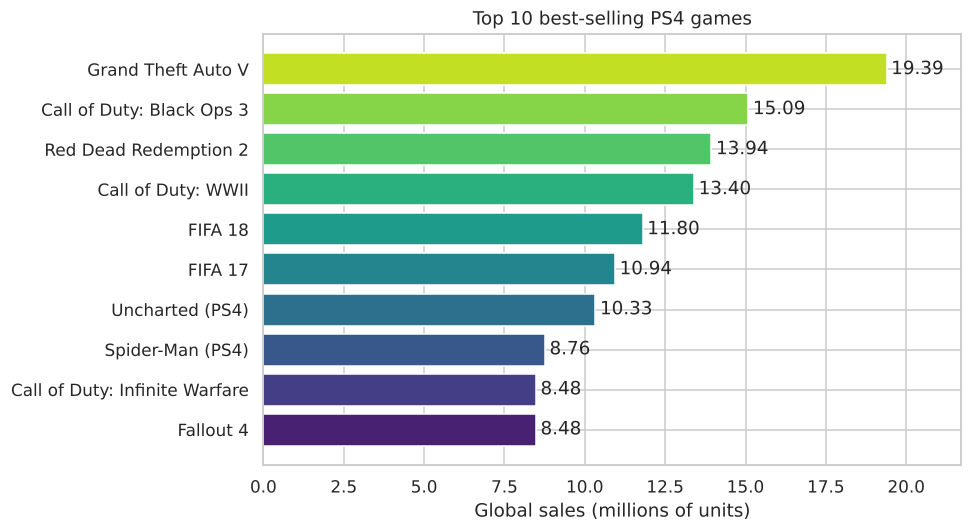

In [8]:
fig, ax = plt.subplots(figsize=(9, 5))
t = top10.iloc[::-1]
bars = ax.barh(t["Game"], t["Global"], color=sns.color_palette("viridis", 10))
ax.bar_label(bars, fmt="%.2f", padding=3)
ax.set_title("Top 10 best-selling PS4 games")
ax.set_xlabel("Global sales (millions of units)")
ax.set_ylabel("")
ax.set_xlim(0, t["Global"].max() * 1.12)
plt.tight_layout(); plt.savefig("figures/01_top10_games.png"); plt.show()

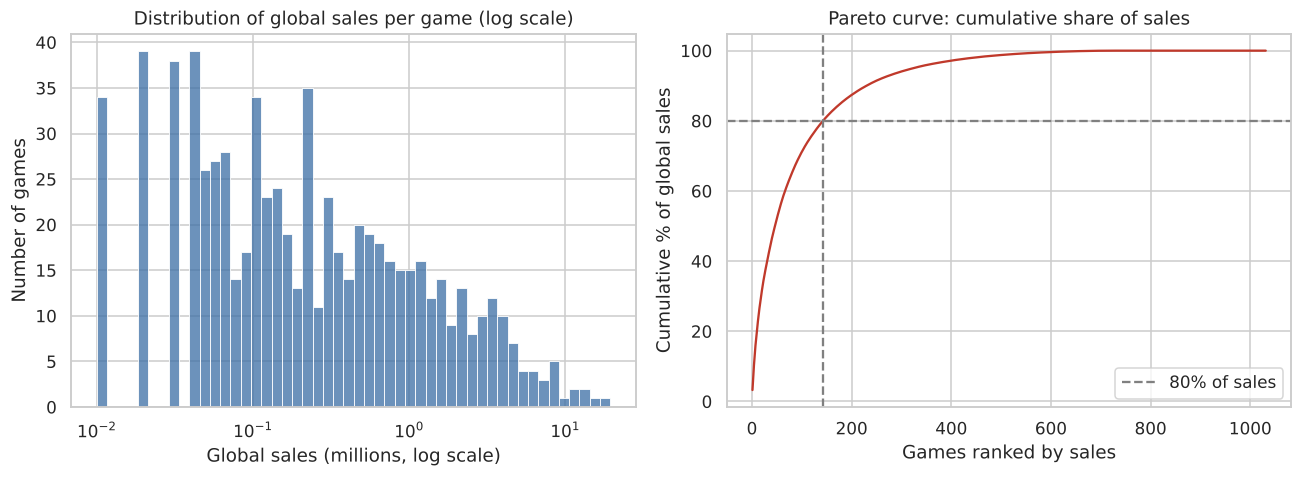

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.histplot(df.loc[df["Has_Sales"], "Global"], bins=50, log_scale=True, ax=axes[0], color="#3b6ea5")
axes[0].set_title("Distribution of global sales per game (log scale)")
axes[0].set_xlabel("Global sales (millions, log scale)"); axes[0].set_ylabel("Number of games")

axes[1].plot(np.arange(1, len(s) + 1), cum_share.values * 100, color="#c0392b")
axes[1].axhline(80, ls="--", color="grey", label="80% of sales")
axes[1].axvline(n80, ls="--", color="grey")
axes[1].set_title("Pareto curve: cumulative share of sales")
axes[1].set_xlabel("Games ranked by sales"); axes[1].set_ylabel("Cumulative % of global sales")
axes[1].legend()
plt.tight_layout(); plt.savefig("figures/02_distribution_pareto.png"); plt.show()

## 5. Platform analysis

The provided file contains a single platform, so there is nothing to compare. The cell below shows the platform summary; if further platform files (e.g. `XboxOne_GameSales.csv`) are concatenated into `df` it will rank them automatically.

In [10]:
platform_summary = (df.groupby("Platform")["Global"]
                      .agg(Games="count", Total_Sales="sum", Mean_Sales="mean")
                      .sort_values("Total_Sales", ascending=False).round(2))
platform_summary

,Games,Total_Sales,Mean_Sales
Platform,,,
PS4,1031,595.64,0.58


## 6. Genre analysis

In [11]:
genre = (df.groupby("Genre")["Global"]
           .agg(Games="count", Total="sum", Mean="mean", Median="median")
           .sort_values("Total", ascending=False))
genre["Share_%"] = (genre["Total"] / genre["Total"].sum() * 100)
genre.round(2)

,Games,Total,Mean,Median,Share_%
Genre,,,,,
Action,256,136.85,0.53,0.06,22.98
Shooter,89,134.99,1.52,0.27,22.66
Sports,71,92.85,1.31,0.56,15.59
Role-Playing,123,62.82,0.51,0.09,10.55
Action-Adventure,40,61.86,1.55,0.41,10.39
Racing,48,25.29,0.53,0.16,4.25
Fighting,35,19.46,0.56,0.25,3.27
Platform,46,17.85,0.39,0.04,3.00
Adventure,97,15.22,0.16,0.03,2.56


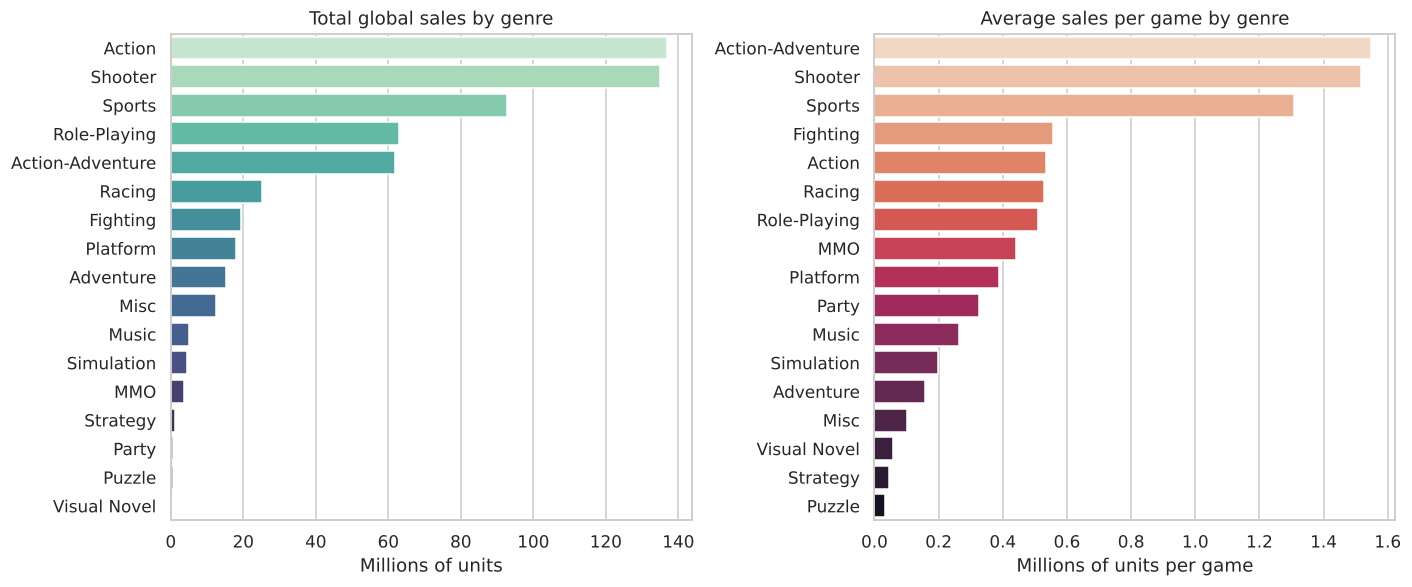

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
order = genre.index
sns.barplot(x=genre["Total"], y=order, ax=axes[0], palette="mako_r", hue=order, legend=False)
axes[0].set_title("Total global sales by genre"); axes[0].set_xlabel("Millions of units"); axes[0].set_ylabel("")

m = genre.sort_values("Mean", ascending=False)
sns.barplot(x=m["Mean"], y=m.index, ax=axes[1], palette="rocket_r", hue=m.index, legend=False)
axes[1].set_title("Average sales per game by genre"); axes[1].set_xlabel("Millions of units per game"); axes[1].set_ylabel("")
plt.tight_layout(); plt.savefig("figures/03_genre_total_vs_mean.png"); plt.show()

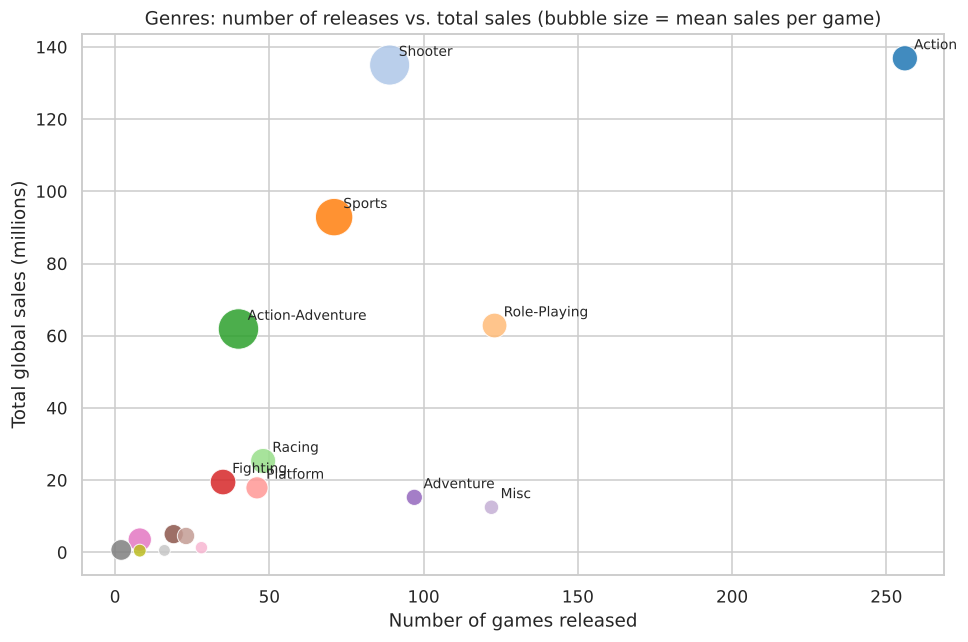

In [13]:
# Volume vs. quality: many releases does not mean high sales
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=genre, x="Games", y="Total", size="Mean", sizes=(60, 700),
                hue=genre.index, legend=False, palette="tab20", ax=ax, alpha=.85)
for name, r in genre.iterrows():
    if r["Total"] > 10:
        ax.annotate(name, (r["Games"], r["Total"]), xytext=(6, 6), textcoords="offset points", fontsize=9)
ax.set_title("Genres: number of releases vs. total sales (bubble size = mean sales per game)")
ax.set_xlabel("Number of games released"); ax.set_ylabel("Total global sales (millions)")
plt.tight_layout(); plt.savefig("figures/04_genre_volume_vs_sales.png"); plt.show()

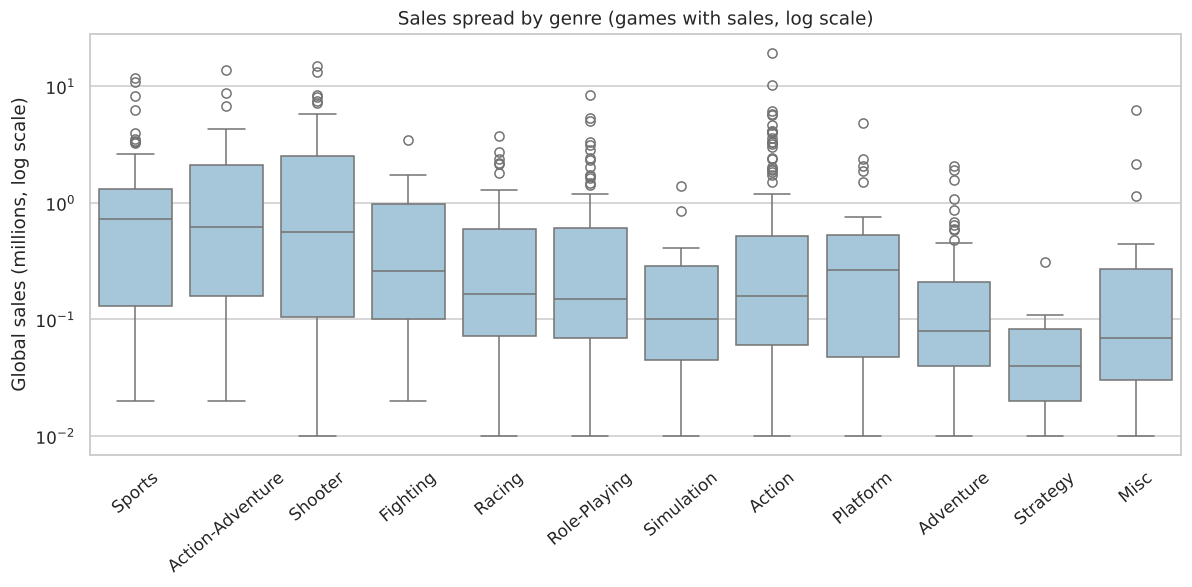

In [14]:
# Spread of sales within the main genres (games with sales only)
main = genre[genre["Games"] >= 20].index
fig, ax = plt.subplots(figsize=(11, 5.5))
sns.boxplot(data=df[df["Genre"].isin(main) & df["Has_Sales"]], x="Genre", y="Global",
            order=genre.loc[main].sort_values("Median", ascending=False).index, ax=ax, color="#9ecae1")
ax.set_yscale("log"); ax.tick_params(axis="x", rotation=40)
ax.set_title("Sales spread by genre (games with sales, log scale)")
ax.set_ylabel("Global sales (millions, log scale)"); ax.set_xlabel("")
plt.tight_layout(); plt.savefig("figures/05_genre_boxplot.png"); plt.show()

## 7. Publisher analysis

In [15]:
pub = (df.groupby("Publisher_Clean")["Global"]
         .agg(Games="count", Total="sum", Mean="mean")
         .sort_values("Total", ascending=False))
pub["Hit_rate_>=1M_%"] = df.groupby("Publisher_Clean")["Global"].apply(lambda x: (x >= 1).mean() * 100)
pub.head(10).round(2)

,Games,Total,Mean,Hit_rate_>=1M_%
Publisher_Clean,,,,
Electronic Arts,40,102.51,2.56,57.50
Sony Interactive Entertainment,72,97.11,1.35,34.72
Activision,30,72.44,2.41,33.33
Ubisoft,45,59.16,1.31,37.78
Warner Bros. Interactive Entertainment,29,34.39,1.19,48.28
Rockstar Games,3,33.93,11.31,66.67
Square Enix,40,29.92,0.75,25.00
Bethesda Softworks,17,28.96,1.70,64.71
Bandai Namco,57,24.87,0.44,12.28


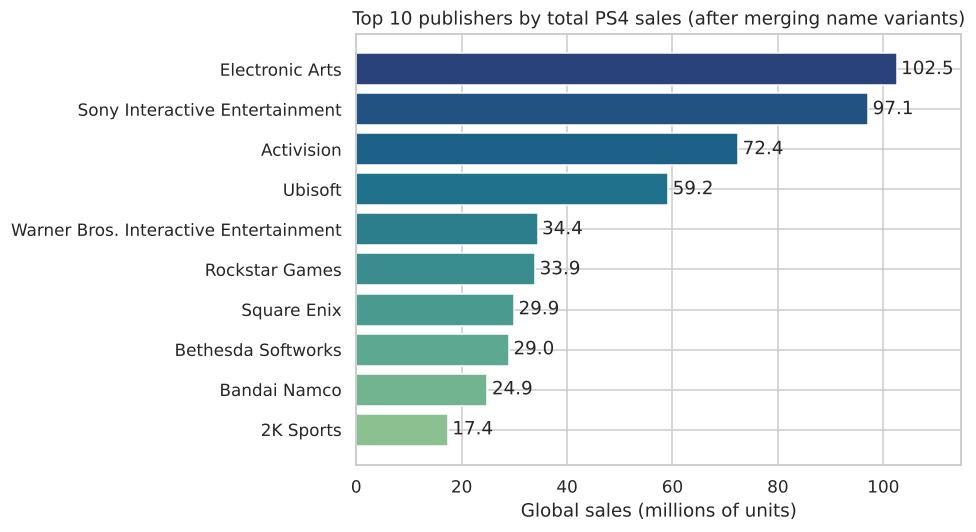

In [16]:
top_pub = pub.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(top_pub.index, top_pub["Total"], color=sns.color_palette("crest", 10))
ax.bar_label(bars, fmt="%.1f", padding=3)
ax.set_title("Top 10 publishers by total PS4 sales (after merging name variants)")
ax.set_xlabel("Global sales (millions of units)"); ax.set_xlim(0, top_pub["Total"].max() * 1.12)
plt.tight_layout(); plt.savefig("figures/06_top_publishers.png"); plt.show()

In [17]:
# Effect of cleaning: ranking by raw labels vs cleaned labels
raw_rank = df.groupby("Publisher")["Global"].sum().sort_values(ascending=False).head(5)
print("Top 5 using raw publisher names:\n", raw_rank.round(2), "\n")
print("Top 5 after merging variants:\n", pub["Total"].head(5).round(2))

Top 5 using raw publisher names:
 Publisher
Activision                        72.44
Ubisoft                           59.16
Electronic Arts                   54.96
Sony Interactive Entertainment    54.85
EA Sports                         47.55
Name: Global, dtype: float64 

Top 5 after merging variants:
 Publisher_Clean
Electronic Arts                           102.51
Sony Interactive Entertainment             97.11
Activision                                 72.44
Ubisoft                                    59.16
Warner Bros. Interactive Entertainment     34.39
Name: Total, dtype: float64


## 8. Regional analysis

In [18]:
reg_tot = df[regions].sum()
reg_share = (reg_tot / df["Global"].sum() * 100).round(1)
pd.DataFrame({"Sales (M)": reg_tot.round(2), "Share %": reg_share})

,Sales (M),Share %
North America,211.57,35.5
Europe,257.17,43.2
Japan,34.78,5.8
Rest of World,92.04,15.5


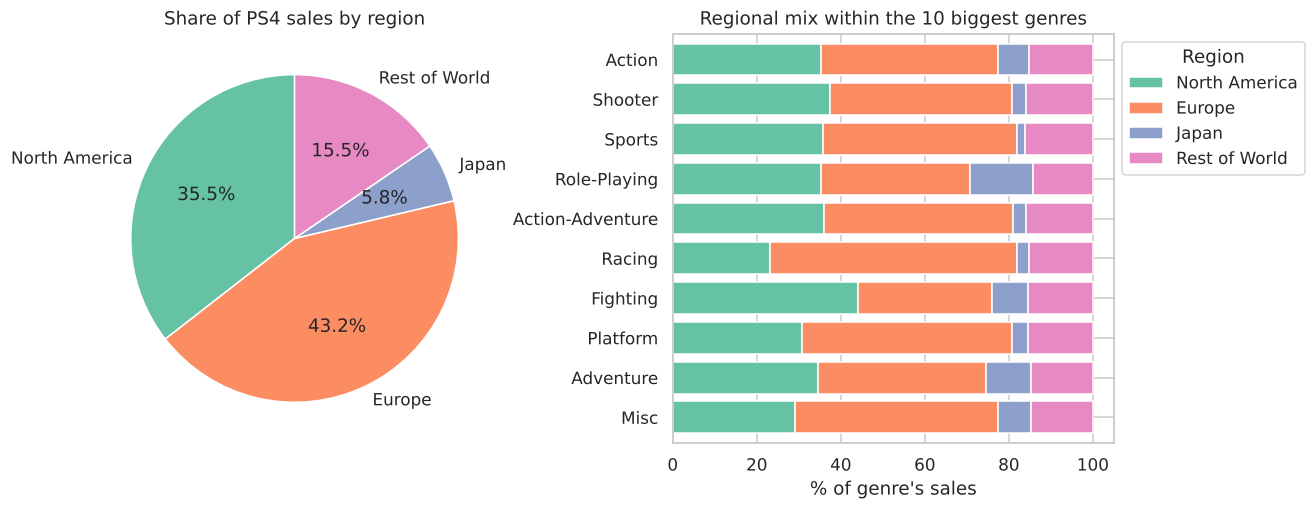

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
axes[0].pie(reg_tot, labels=regions, autopct="%1.1f%%", startangle=90,
            colors=sns.color_palette("Set2", 4), wedgeprops={"edgecolor": "white"})
axes[0].set_title("Share of PS4 sales by region")

gr = df.groupby("Genre")[regions].sum()
gr_share = gr.div(gr.sum(axis=1), axis=0) * 100
gr_share = gr_share.loc[genre.index[:10]]
gr_share.plot(kind="barh", stacked=True, ax=axes[1], color=sns.color_palette("Set2", 4), width=.8)
axes[1].invert_yaxis(); axes[1].set_xlabel("% of genre's sales"); axes[1].set_ylabel("")
axes[1].set_title("Regional mix within the 10 biggest genres"); axes[1].legend(title="Region", bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.savefig("figures/07_regions.png"); plt.show()

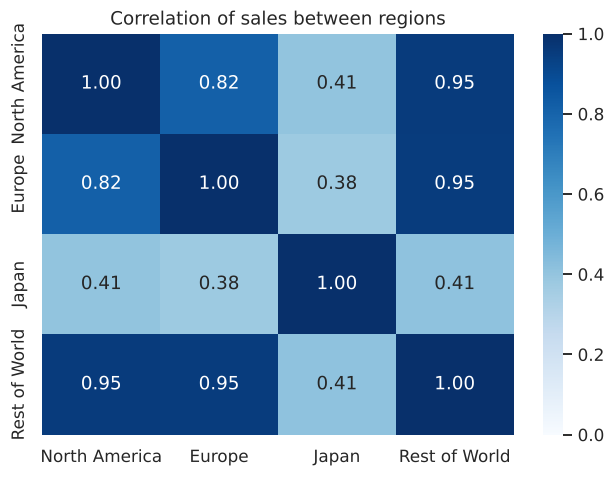

In [20]:
fig, ax = plt.subplots(figsize=(6, 4.5))
sns.heatmap(df[regions].corr(), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax)
ax.set_title("Correlation of sales between regions")
plt.tight_layout(); plt.savefig("figures/08_region_correlation.png"); plt.show()

In [21]:
# Where does Japan differ from the West? Genres with the largest Japan share (min. 1M total sales)
jp = (gr.assign(Japan_share=gr["Japan"] / gr.sum(axis=1) * 100, Total=gr.sum(axis=1))
        .query("Total >= 1").sort_values("Japan_share", ascending=False))
jp[["Total", "Japan_share"]].head(5).round(1)

,Total,Japan_share
Genre,,
Strategy,1.3,26.2
Role-Playing,62.9,15.0
Adventure,15.2,10.8
Fighting,19.4,8.6
Misc,12.5,7.7


## 9. Release-year analysis

In [22]:
yr = (df.dropna(subset=["Year"]).groupby("Year")["Global"]
        .agg(Releases="count", Total="sum", Mean="mean", Hits_1M=lambda x: (x >= 1).sum()))
yr.index = yr.index.astype(int)
yr.round(2)

,Releases,Total,Mean,Hits_1M
Year,,,,
2013,20,28.76,1.44,9
2014,98,115.85,1.18,26
2015,172,133.99,0.78,33
2016,222,135.72,0.61,32
2017,254,130.90,0.52,35
2018,39,50.20,1.29,9
2019,11,0.00,0.00,0
2020,8,0.00,0.00,0


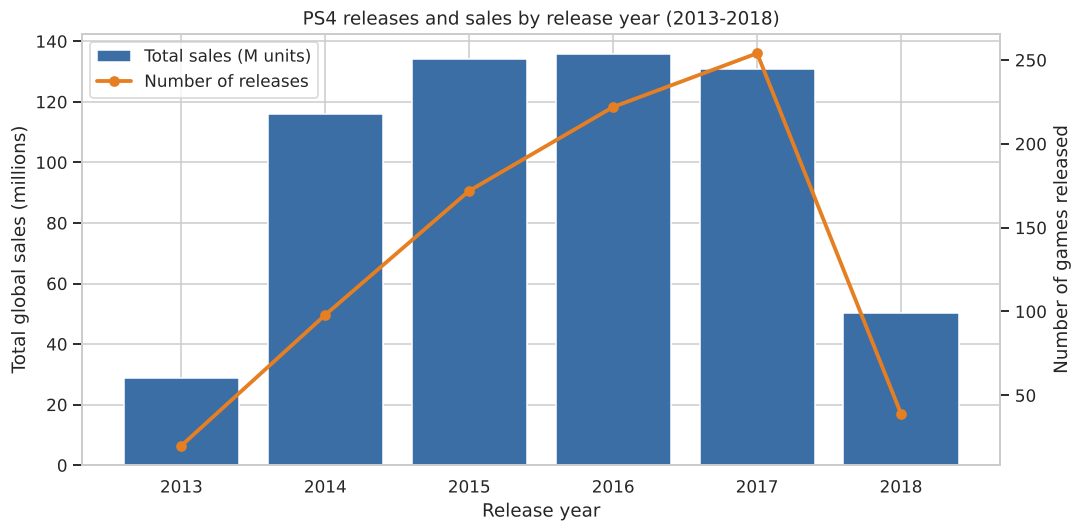

In [23]:
fig, ax1 = plt.subplots(figsize=(10, 5))
yv = yr.loc[2013:2018]
ax1.bar(yv.index, yv["Total"], color="#3b6ea5", label="Total sales (M units)")
ax1.set_xlabel("Release year"); ax1.set_ylabel("Total global sales (millions)")
ax2 = ax1.twinx(); ax2.grid(False)
ax2.plot(yv.index, yv["Releases"], color="#e67e22", marker="o", lw=2.5, label="Number of releases")
ax2.set_ylabel("Number of games released")
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left")
ax1.set_title("PS4 releases and sales by release year (2013-2018)")
plt.tight_layout(); plt.savefig("figures/09_year_trend.png"); plt.show()

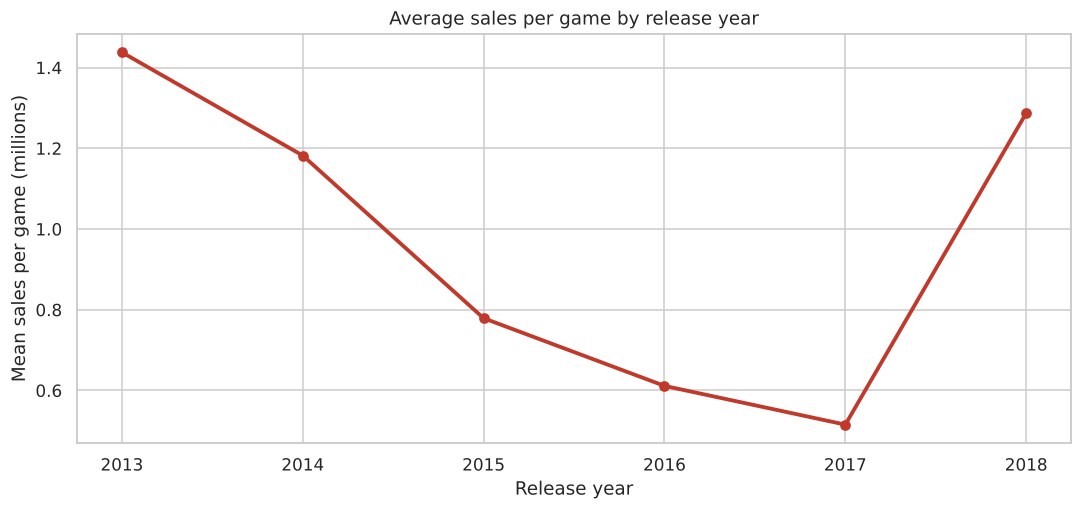

In [24]:
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(yv.index, yv["Mean"], marker="o", lw=2.5, color="#c0392b")
ax.set_title("Average sales per game by release year"); ax.set_xlabel("Release year"); ax.set_ylabel("Mean sales per game (millions)")
plt.tight_layout(); plt.savefig("figures/10_year_mean.png"); plt.show()

,Year,Game,Genre,Global
0,2013,Call of Duty: Ghosts,Shooter,4.17
1,2014,Grand Theft Auto V,Action,19.39
2,2015,Call of Duty: Black Ops 3,Shooter,15.09
3,2016,FIFA 17,Sports,10.94
4,2017,Call of Duty: WWII,Shooter,13.40
5,2018,Red Dead Redemption 2,Action-Adventure,13.94


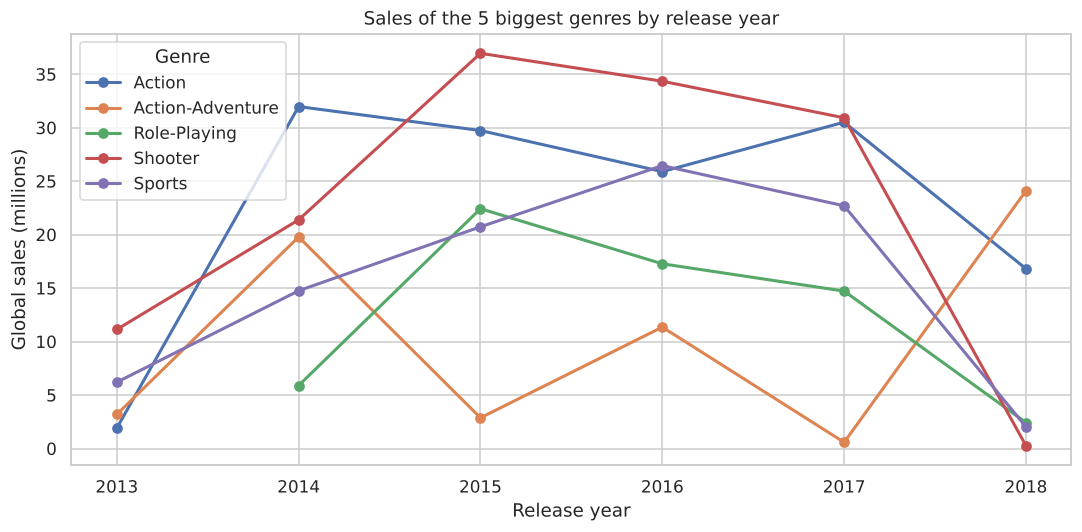

In [25]:
# Best seller of each year, and genre mix by year
best = (df.dropna(subset=["Year"]).query("Global > 0").sort_values("Global", ascending=False)
          .groupby("Year").head(1).sort_values("Year")[["Year", "Game", "Genre", "Global"]])
display(best.reset_index(drop=True))

top_genres = genre.index[:5]
gy = (df[df["Genre"].isin(top_genres)].dropna(subset=["Year"]).query("2013 <= Year <= 2018")
        .pivot_table(index="Year", columns="Genre", values="Global", aggfunc="sum"))
fig, ax = plt.subplots(figsize=(10, 5))
gy.plot(ax=ax, marker="o", lw=2)
ax.set_title("Sales of the 5 biggest genres by release year"); ax.set_ylabel("Global sales (millions)"); ax.set_xlabel("Release year")
ax.legend(title="Genre")
plt.tight_layout(); plt.savefig("figures/11_genre_by_year.png"); plt.show()

## 10. Key insights (computed from the data)

In [26]:
total = df["Global"].sum()
top_game = df.nlargest(1, "Global").iloc[0]
tg = genre.iloc[0]; best_mean = genre[genre["Games"] >= 20].sort_values("Mean", ascending=False).iloc[0]
tp = pub.iloc[0]
eu, na, jpn = reg_share["Europe"], reg_share["North America"], reg_share["Japan"]
print(f"1. Total PS4 sales in the file: {total:,.1f}M units across {len(df):,} titles.")
print(f"2. Best seller: {top_game['Game']} ({top_game['Global']:.2f}M, {top_game['Genre']}, {top_game['Publisher_Clean']}).")
print(f"3. Sales are extremely concentrated: top 10 games = {cum_share[9]:.1%}, top 100 = {cum_share[99]:.1%}; median game sells only {df['Global'].median():.2f}M vs mean {df['Global'].mean():.2f}M.")
print(f"4. Biggest genre by volume: {genre.index[0]} ({tg['Share_%']:.1f}% of sales) but its mean per game is only {tg['Mean']:.2f}M.")
print(f"5. Best genre by average per game (>=20 titles): {best_mean.name} at {best_mean['Mean']:.2f}M per title.")
print(f"6. Top publisher after merging name variants: {pub.index[0]} ({tp['Total']:.1f}M, {tp['Games']:.0f} titles); raw labels would have ranked {raw_rank.index[0]} first.")
print(f"7. Regions: Europe {eu}%, North America {na}%, Rest of World {reg_share['Rest of World']}%, Japan {jpn}%.")
print(f"8. Release years: peak sales in {yr['Total'].loc[2013:2018].idxmax()}, but releases kept growing to {yr['Releases'].loc[2013:2018].idxmax()} while average sales per game fell.")

1. Total PS4 sales in the file: 595.6M units across 1,031 titles.
2. Best seller: Grand Theft Auto V (19.39M, Action, Rockstar Games).
3. Sales are extremely concentrated: top 10 games = 20.2%, top 100 = 71.1%; median game sells only 0.06M vs mean 0.58M.
4. Biggest genre by volume: Action (23.0% of sales) but its mean per game is only 0.53M.
5. Best genre by average per game (>=20 titles): Action-Adventure at 1.55M per title.
6. Top publisher after merging name variants: Electronic Arts (102.5M, 40 titles); raw labels would have ranked Activision first.
7. Regions: Europe 43.2%, North America 35.5%, Rest of World 15.5%, Japan 5.8%.
8. Release years: peak sales in 2016, but releases kept growing to 2017 while average sales per game fell.


### Limitations
* Only PS4 data was provided, so platform comparison could not be performed.
* Sales are units, not revenue; no price or cost data, so profitability is not measurable.
* 209 titles (20%) have no release year; they account for only about 0.04% of sales, so year trends are unaffected.
* Games released 2018+ are likely incomplete (the dataset appears to be a snapshot from around 2018), so 2018 totals and the 2019-2020 zeros should not be read as a decline.